# Tugas UTS: Linear Regression & Logistic Regression
**Mata Kuliah:** Machine Learning

Tugas ini menguji pemahaman Anda tentang materi **Simple Regression** (`simple_regression/regression_1.ipynb`) dan **Simple Classification** (`simple_classification/classification_1.ipynb`). Anda akan menerapkan algoritma yang sama pada **dataset baru**, lalu mengembangkannya dengan evaluasi dan eksperimen tambahan.

**Identitas Mahasiswa**
- Nama  : Alfianus Feri Bouk
- NIM   : 241011400559
- Kelas : Reg B ~~Reg C~~

## 📌 Ketentuan Pengerjaan

1. Kerjakan semua soal di notebook ini pada sel kode / sel markdown yang telah disediakan.
2. **Model dan metrik evaluasi wajib diimplementasikan sendiri** dengan NumPy, seperti pada materi (`train_test_split`, `LinearRegression`, `LinearRegressionGD`, `LogisticRegression`, `accuracy_score`, `confusion_matrix`). Anda boleh menyalin implementasi dari materi.
   - Library yang boleh dipakai: `numpy`, `pandas`, `matplotlib`.
   - `scikit-learn` **tidak boleh** dipakai untuk model dan metrik, kecuali pada soal bonus untuk membandingkan hasil.
3. **`random_state` = 2 digit terakhir NIM Anda** (contoh: NIM `...0347` → `random_state=47`; jika `00`, gunakan `100`). Karena itu, setiap mahasiswa akan mendapat hasil angka yang berbeda.
4. Setiap soal yang meminta **penjelasan/analisis** dijawab dengan kalimat Anda sendiri pada sel markdown, dan harus merujuk ke angka/grafik hasil Anda.
5. Notebook harus **sudah dijalankan** (*Run All*) sehingga semua output dan grafik terlihat saat dibuka di GitHub.

## 📂 Dataset
Dataset disediakan di folder ini:

| File | Kolom | Keterangan |
|---|---|---|
| `Ads_Data.csv` | `BiayaIklan`, `Penjualan` | Biaya iklan per bulan (juta Rp) dan penjualan per bulan (juta Rp), 40 data |
| `Email_Data.csv` | `JumlahLink`, `KataPromo`, `Spam` | Jumlah link dan jumlah kata promosi dalam sebuah email, serta label Spam (1) / Bukan Spam (0), 60 data |

## 📤 Cara Pengumpulan

1. Buat **repositori baru** di akun GitHub Anda masing-masing dengan nama: `uts-machine-learning-<NIM>` (contoh: `uts-machine-learning-20230801047`).
2. Atur repositori menjadi **Public**.
3. Struktur repositori minimal:
   ```
   uts-machine-learning-<NIM>/
   ├── README.md            # Nama, NIM, Kelas, dan ringkasan hasil (R², akurasi, dll)
   ├── tugas_UTS.ipynb      # notebook ini, sudah dijalankan lengkap dengan output
   ├── Ads_Data.csv
   └── Email_Data.csv
   ```
4. Kumpulkan **link repositori GitHub** di halaman **UTS pada Mentari**.
5. Batas waktu pengumpulan (hari terakhir periode UTS):

| Kelas | Batas Pengumpulan |
|---|---|
| **Reg B** | **Jumat, 23 Oktober 2026, pukul 23:59 WIB** |
| **Reg C** | **Sabtu, 24 Oktober 2026, pukul 23:59 WIB** |

> ⚠️ Yang dinilai adalah **commit terakhir sebelum batas waktu**. Commit setelah batas waktu tidak akan dinilai. Pastikan link yang dikumpulkan bisa dibuka (repositori tidak *private*).

## 🧮 Penilaian

| Bagian | Bobot |
|---|---|
| Bagian A – Linear Regression | 35% |
| Bagian B – Logistic Regression | 40% |
| Bagian C – Pemahaman Konsep | 15% |
| Kerapihan repositori, README, dan notebook (output lengkap, kode rapi & diberi komentar) | 10% |
| Bonus – Perbandingan dengan scikit-learn | +5 |

In [1]:
# import Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RANDOM_STATE = 59  # 2 digit terakhir NIM 241011400559

In [2]:
# Fungsi train_test_split (implementasi sendiri dengan NumPy)
def train_test_split(X, y, test_size=0.2, random_state=None):
    """Membagi data menjadi train dan test secara acak (diacak dengan random_state)."""
    X = np.asarray(X)
    y = np.asarray(y)
    n_samples = len(X)
    rng = np.random.RandomState(random_state)
    indices = rng.permutation(n_samples)          # acak urutan data
    n_test = int(round(n_samples * test_size))    # jumlah data testing
    test_idx = indices[:n_test]
    train_idx = indices[n_test:]
    return X[train_idx], X[test_idx], y[train_idx], y[test_idx]

---
# Bagian A – Linear Regression (35%)

Sebuah toko online ingin mengetahui pengaruh **biaya iklan** terhadap **penjualan** setiap bulan. Gunakan dataset `Ads_Data.csv`.

### Soal A1 – Load & Visualisasi Data
1. Baca `Ads_Data.csv` menggunakan pandas dan tampilkan 5 data pertama serta jumlah baris datanya.
2. Pisahkan `X` (`BiayaIklan`) dan `y` (`Penjualan`). Pastikan `X` berbentuk 2 dimensi `(n, 1)`.
3. Buat *scatter plot* `BiayaIklan` vs `Penjualan` (lengkap dengan judul dan label sumbu).

   BiayaIklan  Penjualan
0         0.8       34.3
1         0.9       38.8
2         1.0       33.2
3         1.3       36.0
4         1.7       51.3

Jumlah baris data: 40
Shape X: (40, 1)
Shape y: (40,)


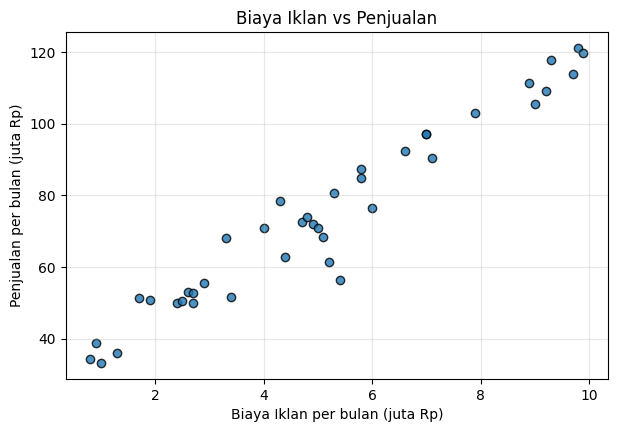

In [3]:
# Jawaban A1
# 1. Baca data
df_ads = pd.read_csv('Ads_Data.csv')
print(df_ads.head())
print('\nJumlah baris data:', len(df_ads))

# 2. Pisahkan X dan y (X harus 2 dimensi (n, 1))
X = df_ads[['BiayaIklan']].values
y = df_ads['Penjualan'].values
print('Shape X:', X.shape)
print('Shape y:', y.shape)

# 3. Scatter plot
plt.figure(figsize=(7, 4.5))
plt.scatter(X, y, color='tab:blue', edgecolor='k', alpha=0.8)
plt.title('Biaya Iklan vs Penjualan')
plt.xlabel('Biaya Iklan per bulan (juta Rp)')
plt.ylabel('Penjualan per bulan (juta Rp)')
plt.grid(alpha=0.3)
plt.show()

### Soal A2 – Split Data
Bagi data menjadi data training dan testing dengan `test_size=0.2` dan `random_state=RANDOM_STATE`. Tampilkan *shape* dari `X_train`, `X_test`, `y_train`, `y_test`.

In [4]:
# Jawaban A2
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print('X_train:', X_train.shape)
print('X_test :', X_test.shape)
print('y_train:', y_train.shape)
print('y_test :', y_test.shape)

X_train: (32, 1)
X_test : (8, 1)
y_train: (32,)
y_test : (8,)


### Soal A3 – Training dengan Normal Equation
1. Latih model `LinearRegression` (normal equation, seperti di materi) menggunakan data training.
2. Tampilkan nilai **intercept** ($b$) dan **koefisien** ($m$), lalu tuliskan persamaan garis regresinya: $\hat{y} = b + mX$.
3. **Interpretasikan** arti nilai $m$ dalam konteks kasus ini (misal: "setiap kenaikan biaya iklan 1 juta Rp, penjualan naik sebesar ...").

In [5]:
# Jawaban A3
class LinearRegression:
    """Linear Regression dengan Normal Equation: theta = (X^T X)^-1 X^T y"""
    def fit(self, X, y):
        Xb = np.c_[np.ones(len(X)), X]                 # tambah kolom bias (angka 1)
        theta = np.linalg.pinv(Xb.T @ Xb) @ Xb.T @ y   # normal equation
        self.intercept_ = theta[0]
        self.coef_ = theta[1:]
        return self

    def predict(self, X):
        return self.intercept_ + X @ self.coef_

lin_reg = LinearRegression().fit(X_train, y_train)
b = lin_reg.intercept_
m = lin_reg.coef_[0]
print(f'Intercept (b) : {b:.4f}')
print(f'Koefisien (m) : {m:.4f}')
print(f'Persamaan     : y_hat = {b:.4f} + {m:.4f} * X')

Intercept (b) : 27.7414
Koefisien (m) : 9.0967
Persamaan     : y_hat = 27.7414 + 9.0967 * X


**Jawaban A3 (interpretasi):**

Persamaan regresinya adalah $\hat{y} = 27.7414 + 9.0967X$. Nilai $m = 9.0967$ artinya setiap kenaikan biaya iklan sebesar 1 juta Rp, penjualan per bulan diperkirakan naik sekitar 9.10 juta Rp (dengan asumsi faktor lain tetap). Nilai intercept $b = 27.74$ adalah perkiraan penjualan ketika biaya iklan 0, yaitu penjualan dasar toko tanpa iklan (misalnya dari pelanggan tetap).

### Soal A4 – Evaluasi Model
Pada materi belum ada evaluasi untuk model regresi. **Implementasikan sendiri** fungsi-fungsi berikut menggunakan NumPy:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i| \qquad
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2 \qquad
RMSE = \sqrt{MSE}
$$

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}
$$

1. Hitung MAE, MSE, RMSE, dan $R^2$ pada **data training** dan **data testing**.
2. Tampilkan hasilnya dalam satu tabel (boleh pakai `pd.DataFrame`).
3. Jelaskan arti nilai RMSE dan $R^2$ yang Anda dapatkan. Apakah model ini sudah baik?

In [6]:
# Jawaban A4
def mean_absolute_error(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred))

def mean_squared_error(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

def root_mean_squared_error(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

def r2_score(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1 - ss_res / ss_tot

y_pred_train = lin_reg.predict(X_train)
y_pred_test = lin_reg.predict(X_test)

hasil_eval = pd.DataFrame({
    'MAE':  [mean_absolute_error(y_train, y_pred_train), mean_absolute_error(y_test, y_pred_test)],
    'MSE':  [mean_squared_error(y_train, y_pred_train), mean_squared_error(y_test, y_pred_test)],
    'RMSE': [root_mean_squared_error(y_train, y_pred_train), root_mean_squared_error(y_test, y_pred_test)],
    'R2':   [r2_score(y_train, y_pred_train), r2_score(y_test, y_pred_test)],
}, index=['Training', 'Testing'])
print(hasil_eval.round(4))
print('\nRata-rata Penjualan (y):', round(y.mean(), 2), '| Std:', round(y.std(), 2))

             MAE      MSE    RMSE      R2
Training  4.5471  37.6723  6.1378  0.9423
Testing   4.7274  30.9590  5.5641  0.9231

Rata-rata Penjualan (y): 74.27 | Std: 25.19


**Jawaban A4 (analisis):**

RMSE pada data testing adalah 5.56 juta Rp, artinya rata-rata prediksi model meleset sekitar 5.6 juta dari penjualan sebenarnya. Angka ini kecil dibandingkan rata-rata penjualan (74.27 juta) dan simpangan baku penjualan (25.19 juta). Nilai $R^2$ testing 0.923 berarti sekitar 92.3% variasi penjualan dapat dijelaskan oleh biaya iklan. Nilai $R^2$ training (0.942) dan testing (0.923) berdekatan, sehingga tidak ada tanda overfitting. Menurut saya model ini sudah cukup baik untuk satu fitur saja, walaupun data testing hanya 8 baris sehingga hasilnya masih bisa berubah jika pembagian datanya berbeda.

### Soal A5 – Gradient Descent & Learning Rate
1. Latih model `LinearRegressionGD` (dari materi) dengan `n_iterations=5000` menggunakan **3 nilai learning rate**: `0.001`, `0.02`, dan `0.1`.
2. Untuk setiap learning rate, tampilkan intercept dan koefisien akhirnya, lalu bandingkan dengan hasil normal equation (Soal A3).
3. Buat grafik **loss (MSE) vs iterasi** untuk ketiga learning rate (boleh dalam satu grafik atau *subplot*; gunakan skala log jika perlu).
4. Jelaskan apa yang terjadi pada masing-masing learning rate: mana yang **terlalu lambat**, mana yang **pas**, dan mana yang **gagal konvergen (divergen)**? Mengapa bisa terjadi?

> *Tips: jika muncul `RuntimeWarning: overflow`, itu adalah bagian dari hasil eksperimen. Jelaskan artinya.*

Normal Equation : b = 27.7414, m = 9.0967

GD lr = 0.001 : b = 25.357299811568815, m = 9.47493760894171, loss akhir = 39.05763427969655
GD lr = 0.02  : b = 27.74136692537671, m = 9.096724696930714, loss akhir = 37.672288613421756
GD lr = 0.1   : b = nan, m = nan, loss akhir = nan


cell17:16: RuntimeWarning: overflow encountered in square
/usr/local/lib/python3.12/dist-packages/numpy/_core/_methods.py:132: RuntimeWarning: overflow encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)
cell17:19: RuntimeWarning: overflow encountered in matmul
cell17:19: RuntimeWarning: invalid value encountered in subtract
/usr/local/lib/python3.12/dist-packages/matplotlib/scale.py:270: RuntimeWarning: overflow encountered in power
  return np.power(self.base, values)


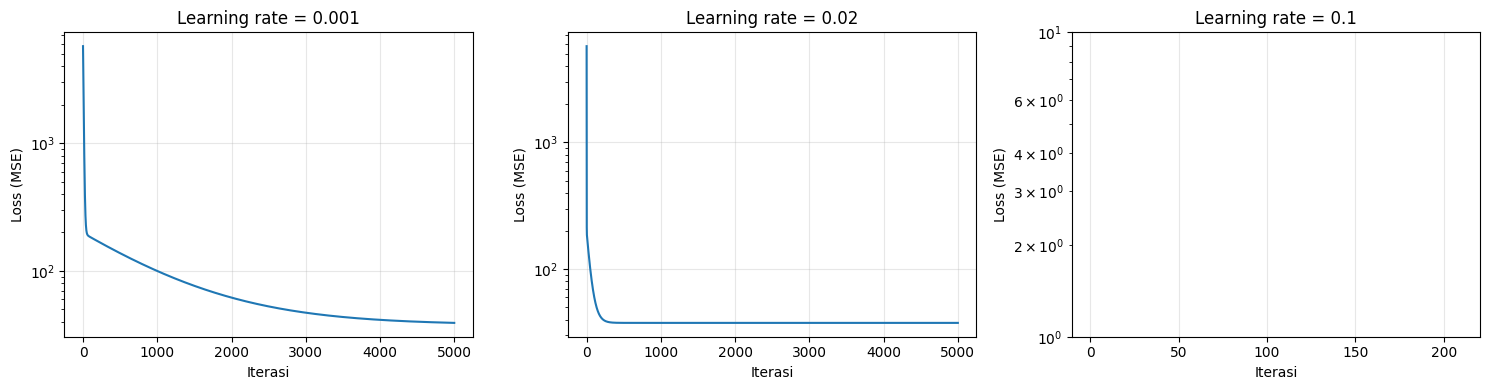

In [7]:
# Jawaban A5
class LinearRegressionGD:
    """Linear Regression dengan Gradient Descent (loss = MSE)."""
    def __init__(self, learning_rate=0.01, n_iterations=1000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations

    def fit(self, X, y):
        n = len(X)
        self.intercept_ = 0.0
        self.coef_ = np.zeros(X.shape[1])
        self.loss_history = []
        for _ in range(self.n_iterations):
            y_pred = self.intercept_ + X @ self.coef_
            error = y_pred - y
            self.loss_history.append(np.mean(error ** 2))      # MSE
            # gradien dari MSE
            self.intercept_ -= self.learning_rate * (2 / n) * np.sum(error)
            self.coef_ -= self.learning_rate * (2 / n) * (X.T @ error)
        return self

    def predict(self, X):
        return self.intercept_ + X @ self.coef_

learning_rates = [0.001, 0.02, 0.1]
gd_models = {}
print(f'Normal Equation : b = {lin_reg.intercept_:.4f}, m = {lin_reg.coef_[0]:.4f}\n')
for lr in learning_rates:
    gd_models[lr] = LinearRegressionGD(learning_rate=lr, n_iterations=5000).fit(X_train, y_train)
    mdl = gd_models[lr]
    print(f'GD lr = {lr:<6}: b = {mdl.intercept_}, m = {mdl.coef_[0]}, loss akhir = {mdl.loss_history[-1]}')

# Grafik loss vs iterasi
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, lr in zip(axes, learning_rates):
    loss = np.array(gd_models[lr].loss_history, dtype=float)
    loss[~np.isfinite(loss)] = np.nan          # inf/nan tidak bisa digambar
    ax.plot(loss)
    ax.set_yscale('log')
    ax.set_title(f'Learning rate = {lr}')
    ax.set_xlabel('Iterasi')
    ax.set_ylabel('Loss (MSE)')
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Jawaban A5 (analisis):**

Hasil normal equation: $b = 27.7414$, $m = 9.0967$.

- **lr = 0.001 (terlalu lambat):** setelah 5000 iterasi hasilnya $b = 25.357$, $m = 9.475$ dan loss 39.06, masih di atas loss optimum 37.67. Loss memang turun terus, tetapi langkahnya terlalu kecil sehingga belum sampai ke titik minimum.
- **lr = 0.02 (pas):** hasilnya $b = 27.7414$ dan $m = 9.0967$, identik dengan normal equation. Loss turun cepat dan sudah stabil di 37.67 sejak sekitar iterasi ke-1000.
- **lr = 0.1 (divergen):** loss justru membesar, dari 5759 menjadi 154.020, lalu 4,2 juta, dan seterusnya, sampai bernilai `inf` pada iterasi ke-211 dan akhirnya `nan` (b dan m juga `nan`). Pada grafik, kurva lr = 0.1 hanya tampak di bagian awal sebelum nilainya meledak.

Penyebabnya adalah ukuran langkah. Jika learning rate terlalu besar, update melompati titik minimum ke sisi seberang dan jaraknya malah lebih jauh dari sebelumnya, sehingga kesalahan membesar di setiap iterasi. Karena fitur `BiayaIklan` tidak di-scaling (nilainya sampai 9.9), gradiennya besar sehingga batas learning rate yang aman cukup kecil (sekitar 0.03 pada data ini). `RuntimeWarning: overflow` berarti angkanya sudah melebihi batas terbesar yang bisa disimpan komputer (float64), yaitu tanda bahwa gradient descent gagal konvergen.

### Soal A6 – Visualisasi & Prediksi
1. Buat grafik *scatter* data **testing** beserta **garis regresi** hasil model (Soal A3).
2. Prediksi penjualan jika biaya iklan sebesar **4.5 juta**, **7 juta**, dan **12 juta**.
3. Prediksi untuk 12 juta berada **di luar rentang data** (ekstrapolasi). Menurut Anda, seberapa bisa dipercaya hasil prediksi tersebut? Jelaskan.

Biaya iklan  4.5 juta -> prediksi penjualan = 68.68 juta
Biaya iklan  7.0 juta -> prediksi penjualan = 91.42 juta
Biaya iklan 12.0 juta -> prediksi penjualan = 136.90 juta

Rentang biaya iklan pada data: 0.8 sampai 9.9


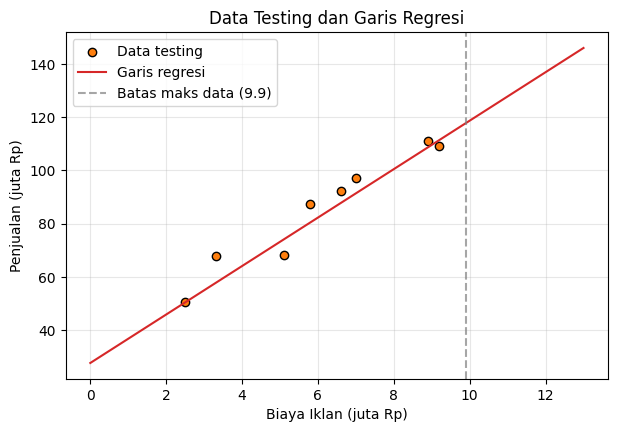

In [8]:
# Jawaban A6
# 1. Scatter data testing + garis regresi
x_line = np.linspace(0, 13, 100).reshape(-1, 1)
plt.figure(figsize=(7, 4.5))
plt.scatter(X_test, y_test, color='tab:orange', edgecolor='k', label='Data testing')
plt.plot(x_line, lin_reg.predict(x_line), color='tab:red', label='Garis regresi')
plt.axvline(X.max(), color='gray', linestyle='--', alpha=0.7, label='Batas maks data (9.9)')
plt.title('Data Testing dan Garis Regresi')
plt.xlabel('Biaya Iklan (juta Rp)')
plt.ylabel('Penjualan (juta Rp)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# 2. Prediksi
biaya_baru = np.array([[4.5], [7.0], [12.0]])
prediksi = lin_reg.predict(biaya_baru)
for biaya, p in zip(biaya_baru.ravel(), prediksi):
    print(f'Biaya iklan {biaya:>4} juta -> prediksi penjualan = {p:.2f} juta')
print('\nRentang biaya iklan pada data:', X.min(), 'sampai', X.max())

**Jawaban A6 (analisis):**

Prediksi penjualan: biaya iklan 4.5 juta → 68.68 juta, 7 juta → 91.42 juta, dan 12 juta → 136.90 juta.

Prediksi untuk 4.5 dan 7 juta berada di dalam rentang data (0.8 sampai 9.9 juta), sehingga cukup bisa dipercaya. Prediksi untuk 12 juta adalah ekstrapolasi karena melewati nilai maksimum data. Hasil 136.90 juta kurang bisa dipercaya karena model hanya belajar dari pola di rentang 0.8–9.9 juta, dan kita tidak tahu apakah hubungan linear tetap berlaku di luar rentang itu. Pada kenyataannya, pengaruh iklan bisa melandai (*diminishing returns*) karena pasar mulai jenuh, sehingga penjualan sebenarnya bisa lebih rendah dari 136.90 juta. Prediksi ini hanya boleh dipakai sebagai perkiraan kasar.

---
# Bagian B – Logistic Regression (40%)

Sebuah layanan email ingin membuat filter **spam** sederhana berdasarkan **jumlah link** dan **jumlah kata promosi** (misal: "gratis", "diskon", "promo") di dalam email. Gunakan dataset `Email_Data.csv`.

### Soal B1 – Load & Visualisasi Data
1. Baca `Email_Data.csv`, tampilkan 5 data pertama, dan hitung **jumlah email Spam dan Bukan Spam**.
2. Pisahkan `X` (`JumlahLink`, `KataPromo`) dan `y` (`Spam`).
3. Buat *scatter plot* `JumlahLink` vs `KataPromo` dengan warna berbeda untuk Spam dan Bukan Spam (lengkap dengan legend).

   JumlahLink  KataPromo  Spam
0           0          0     0
1           2          4     0
2           6          7     1
3          10          8     1
4           8          7     1

Jumlah baris data: 60

Jumlah per kelas:
Spam
Bukan Spam (0)    35
Spam (1)          25
Name: count, dtype: int64

Shape X: (60, 2) | Shape y: (60,)


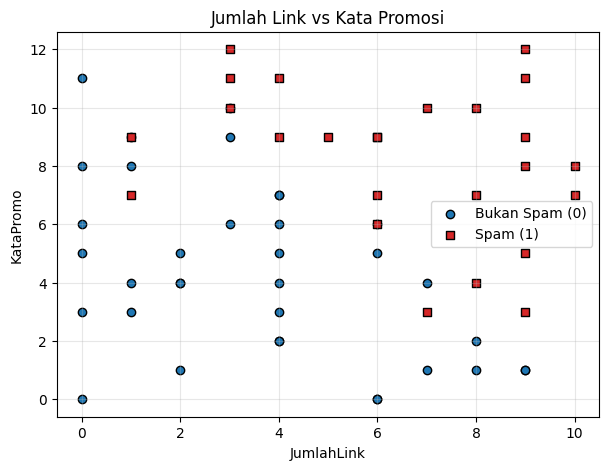

In [9]:
# Jawaban B1
df_email = pd.read_csv('Email_Data.csv')
print(df_email.head())
print('\nJumlah baris data:', len(df_email))
print('\nJumlah per kelas:')
print(df_email['Spam'].value_counts().rename({0: 'Bukan Spam (0)', 1: 'Spam (1)'}))

X = df_email[['JumlahLink', 'KataPromo']].values
y = df_email['Spam'].values
print('\nShape X:', X.shape, '| Shape y:', y.shape)

plt.figure(figsize=(7, 5))
plt.scatter(X[y == 0, 0], X[y == 0, 1], color='tab:blue', edgecolor='k', label='Bukan Spam (0)')
plt.scatter(X[y == 1, 0], X[y == 1, 1], color='tab:red', marker='s', edgecolor='k', label='Spam (1)')
plt.title('Jumlah Link vs Kata Promosi')
plt.xlabel('JumlahLink')
plt.ylabel('KataPromo')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Soal B2 – Split Data & Training
1. Bagi data dengan `test_size=0.25` dan `random_state=RANDOM_STATE`.
2. Latih model `LogisticRegression` (gradient descent, dari materi) dengan `learning_rate=0.1` dan `n_iterations=10000`.
3. Tampilkan intercept ($b$) dan koefisien ($m_1, m_2$), lalu tuliskan persamaannya:
   $$P(\text{Spam}) = \sigma(b + m_1 \cdot \text{JumlahLink} + m_2 \cdot \text{KataPromo})$$
4. Buat grafik **log loss vs iterasi**. Apakah loss sudah turun dan stabil?

X_train: (45, 2) | X_test: (15, 2)
Intercept (b)    : -11.5670
Koefisien m1 (JumlahLink): 1.0532
Koefisien m2 (KataPromo) : 0.9422
P(Spam) = sigmoid(-11.5670 + 1.0532 * JumlahLink + 0.9422 * KataPromo)
Log loss awal : 0.6931
Log loss akhir: 0.2645


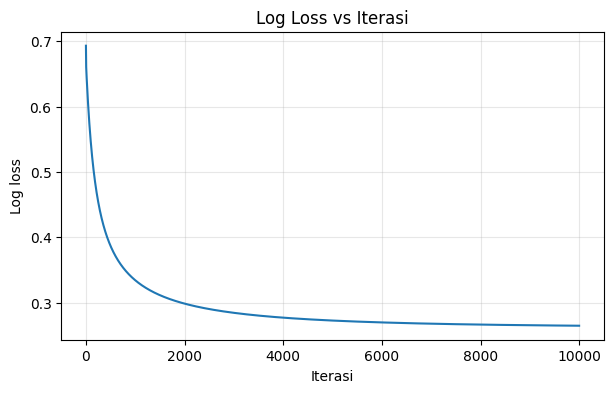

In [10]:
# Jawaban B2
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=RANDOM_STATE)
print('X_train:', X_train.shape, '| X_test:', X_test.shape)

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

class LogisticRegression:
    """Logistic Regression dengan Gradient Descent (loss = log loss)."""
    def __init__(self, learning_rate=0.1, n_iterations=1000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations

    def fit(self, X, y):
        n = len(X)
        self.intercept_ = 0.0
        self.coef_ = np.zeros(X.shape[1])
        self.loss_history = []
        eps = 1e-15
        for _ in range(self.n_iterations):
            p = sigmoid(self.intercept_ + X @ self.coef_)
            p_clip = np.clip(p, eps, 1 - eps)
            loss = -np.mean(y * np.log(p_clip) + (1 - y) * np.log(1 - p_clip))
            self.loss_history.append(loss)
            error = p - y
            self.intercept_ -= self.learning_rate * np.mean(error)
            self.coef_ -= self.learning_rate * (X.T @ error) / n
        return self

    def predict_proba(self, X):
        return sigmoid(self.intercept_ + X @ self.coef_)

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

log_reg = LogisticRegression(learning_rate=0.1, n_iterations=10000).fit(X_train, y_train)
b = log_reg.intercept_
m1, m2 = log_reg.coef_
print(f'Intercept (b)    : {b:.4f}')
print(f'Koefisien m1 (JumlahLink): {m1:.4f}')
print(f'Koefisien m2 (KataPromo) : {m2:.4f}')
print(f'P(Spam) = sigmoid({b:.4f} + {m1:.4f} * JumlahLink + {m2:.4f} * KataPromo)')
print(f'Log loss awal : {log_reg.loss_history[0]:.4f}')
print(f'Log loss akhir: {log_reg.loss_history[-1]:.4f}')

plt.figure(figsize=(7, 4))
plt.plot(log_reg.loss_history)
plt.title('Log Loss vs Iterasi')
plt.xlabel('Iterasi')
plt.ylabel('Log loss')
plt.grid(alpha=0.3)
plt.show()

**Jawaban B2 (analisis):**

Persamaannya: $P(\text{Spam}) = \sigma(-11.5670 + 1.0532 \cdot \text{JumlahLink} + 0.9422 \cdot \text{KataPromo})$.

Kedua koefisien positif, artinya makin banyak link dan kata promosi, makin besar peluang email dianggap spam. Setiap tambahan 1 link menaikkan *odds* spam sekitar $e^{1.0532} \approx 2.87$ kali, dan setiap tambahan 1 kata promosi sekitar $e^{0.9422} \approx 2.57$ kali.

Grafik log loss turun tajam di awal, dari 0.6931 (sama dengan $\ln 2$, yaitu tebakan acak 50:50) menjadi 0.334 pada iterasi 1000 dan 0.2724 pada iterasi 5000. Pada iterasi 10000 loss mencapai 0.2645, dan selisihnya dari iterasi 9000 hanya sekitar 0.0007. Jadi loss sudah turun dan hampir stabil, walaupun masih menurun sangat pelan.

### Soal B3 – Evaluasi Model
Selain `accuracy_score` dan `confusion_matrix` dari materi, **implementasikan sendiri** fungsi berikut:

$$
Precision = \frac{TP}{TP + FP} \qquad
Recall = \frac{TP}{TP + FN} \qquad
F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}
$$

1. Hitung accuracy, confusion matrix, precision, recall, dan F1-score pada **data testing**.
2. Jelaskan arti nilai **FP** (*false positive*) dan **FN** (*false negative*) pada kasus filter spam. Kesalahan mana yang menurut Anda **lebih merugikan pengguna email**? Mengapa?

In [11]:
# Jawaban B3
def accuracy_score(y_true, y_pred):
    return np.mean(y_true == y_pred)

def confusion_matrix(y_true, y_pred):
    """Mengembalikan [[TN, FP], [FN, TP]]"""
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    tp = np.sum((y_true == 1) & (y_pred == 1))
    return np.array([[tn, fp], [fn, tp]])

def precision_score(y_true, y_pred):
    tp = np.sum((y_true == 1) & (y_pred == 1))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    return tp / (tp + fp) if (tp + fp) > 0 else 0.0

def recall_score(y_true, y_pred):
    tp = np.sum((y_true == 1) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    return tp / (tp + fn) if (tp + fn) > 0 else 0.0

def f1_score(y_true, y_pred):
    p = precision_score(y_true, y_pred)
    r = recall_score(y_true, y_pred)
    return 2 * p * r / (p + r) if (p + r) > 0 else 0.0

y_pred_test = log_reg.predict(X_test)
cm = confusion_matrix(y_test, y_pred_test)
print('Accuracy :', round(accuracy_score(y_test, y_pred_test), 4))
print('Precision:', round(precision_score(y_test, y_pred_test), 4))
print('Recall   :', round(recall_score(y_test, y_pred_test), 4))
print('F1-score :', round(f1_score(y_test, y_pred_test), 4))
print('\nConfusion matrix (baris = aktual, kolom = prediksi):')
print(pd.DataFrame(cm, index=['Aktual Bukan Spam', 'Aktual Spam'], columns=['Prediksi Bukan Spam', 'Prediksi Spam']))

Accuracy : 0.9333
Precision: 1.0
Recall   : 0.75
F1-score : 0.8571

Confusion matrix (baris = aktual, kolom = prediksi):
                   Prediksi Bukan Spam  Prediksi Spam
Aktual Bukan Spam                   11              0
Aktual Spam                          1              3


**Jawaban B3 (analisis):**

Pada data testing (15 email), accuracy = 0.9333 (14 dari 15 benar), precision = 1.0, recall = 0.75, dan F1 = 0.8571. Confusion matrix: TN = 11, FP = 0, FN = 1, TP = 3.

- **FP (false positive):** email yang sebenarnya bukan spam tetapi diprediksi spam, misalnya email penting dari dosen atau tempat kerja yang masuk ke folder spam.
- **FN (false negative):** email spam yang lolos dan diprediksi bukan spam, sehingga tetap muncul di inbox.

Menurut saya **FP lebih merugikan**. Email penting yang salah dibuang atau tersembunyi bisa membuat pengguna ketinggalan informasi (jadwal, tagihan, lowongan), dan pengguna jarang memeriksa folder spam. Sebaliknya FN hanya mengganggu karena pengguna tinggal menghapus email spam tersebut. Model ini tidak punya FP, dan hanya 1 spam yang lolos (FN).

### Soal B4 – Decision Boundary
1. Hitung persamaan **decision boundary** (garis saat probabilitas = 0.5):
   $$b + m_1 x_1 + m_2 x_2 = 0 \;\Rightarrow\; x_2 = -\frac{b + m_1 x_1}{m_2}$$
2. Buat visualisasi data **testing** beserta *background* probabilitas (`contourf`) dan garis decision boundary, seperti di materi.
3. Tunjukkan (beri tanda/penjelasan) data testing mana saja yang **salah diklasifikasikan**.

Decision boundary: KataPromo = -(-11.5670 + 1.0532 * JumlahLink) / 0.9422
                 = 12.2772 + (-1.1179) * JumlahLink
Data testing yang salah diklasifikasikan:
 JumlahLink  KataPromo  Aktual  Prediksi  P(Spam)
          1          7       1         0    0.019


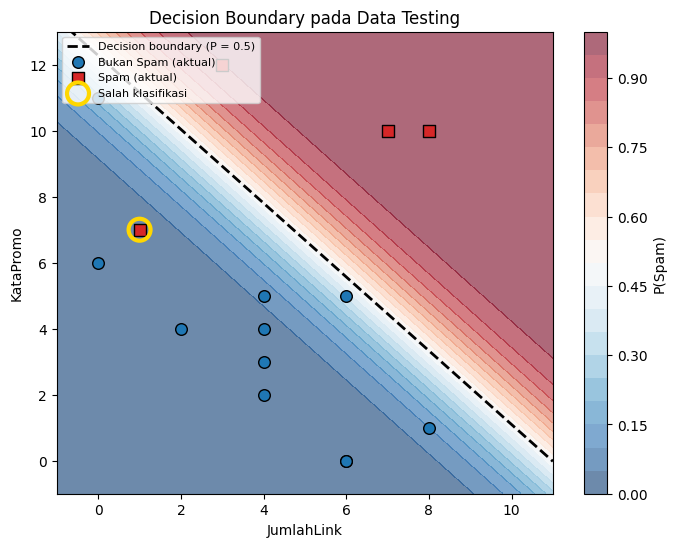

In [12]:
# Jawaban B4
# 1. Persamaan decision boundary: x2 = -(b + m1*x1) / m2
b = log_reg.intercept_
m1, m2 = log_reg.coef_
print(f'Decision boundary: KataPromo = -({b:.4f} + {m1:.4f} * JumlahLink) / {m2:.4f}')
print(f'                 = {-b/m2:.4f} + ({-m1/m2:.4f}) * JumlahLink')

# 2. Visualisasi
x1_grid, x2_grid = np.meshgrid(np.linspace(-1, 11, 300), np.linspace(-1, 13, 300))
grid = np.c_[x1_grid.ravel(), x2_grid.ravel()]
prob_grid = log_reg.predict_proba(grid).reshape(x1_grid.shape)

plt.figure(figsize=(8, 6))
cs = plt.contourf(x1_grid, x2_grid, prob_grid, levels=20, cmap='RdBu_r', alpha=0.6)
plt.colorbar(cs, label='P(Spam)')
x1_line = np.linspace(-1, 11, 100)
plt.plot(x1_line, -(b + m1 * x1_line) / m2, 'k--', linewidth=2, label='Decision boundary (P = 0.5)')
plt.scatter(X_test[y_test == 0, 0], X_test[y_test == 0, 1], color='tab:blue', edgecolor='k', s=70, label='Bukan Spam (aktual)')
plt.scatter(X_test[y_test == 1, 0], X_test[y_test == 1, 1], color='tab:red', marker='s', edgecolor='k', s=70, label='Spam (aktual)')

# 3. Tandai data yang salah klasifikasi
salah = y_test != y_pred_test
plt.scatter(X_test[salah, 0], X_test[salah, 1], s=250, facecolors='none', edgecolors='gold', linewidths=3, label='Salah klasifikasi')
plt.xlim(-1, 11); plt.ylim(-1, 13)
plt.title('Decision Boundary pada Data Testing')
plt.xlabel('JumlahLink'); plt.ylabel('KataPromo')
plt.legend(loc='upper left', fontsize=8)
plt.show()

print('Data testing yang salah diklasifikasikan:')
df_salah = pd.DataFrame({
    'JumlahLink': X_test[salah, 0], 'KataPromo': X_test[salah, 1],
    'Aktual': y_test[salah], 'Prediksi': y_pred_test[salah],
    'P(Spam)': log_reg.predict_proba(X_test[salah]).round(3)})
print(df_salah.to_string(index=False))

**Jawaban B4 (analisis):**

Persamaan decision boundary: $x_2 = 12.2772 - 1.1179 \, x_1$, yaitu KataPromo = 12.2772 − 1.1179 × JumlahLink. Email di atas garis (banyak link dan/atau kata promosi) diprediksi spam, dan email di bawah garis diprediksi bukan spam.

Hanya ada **1 data testing yang salah diklasifikasikan** (ditandai lingkaran emas pada grafik): email dengan JumlahLink = 1 dan KataPromo = 7 yang aslinya spam, tetapi diprediksi bukan spam dengan P(Spam) hanya 0.019. Email ini berada jauh di bawah garis karena jumlah linknya sangat sedikit. Kesalahan ini wajar, sebab data memang tumpang tindih (misalnya masih ada email dengan 1 link dan 9 kata promosi yang bukan spam) dan batas keputusan model berbentuk garis lurus, sehingga tidak bisa memisahkan semua titik dengan sempurna.

### Soal B5 – Eksperimen Threshold
Secara default, model memprediksi Spam jika $P(\text{Spam}) \geq 0.5$.

1. Gunakan `predict_proba` lalu buat prediksi dengan threshold **0.3**, **0.5**, dan **0.7**.
2. Untuk setiap threshold, hitung confusion matrix, precision, dan recall. Tampilkan dalam satu tabel.
3. Jelaskan pengaruh menaikkan/menurunkan threshold terhadap precision dan recall. Berdasarkan jawaban Anda di Soal B3, **threshold mana yang Anda pilih** untuk filter spam? Beri alasan.

In [13]:
# Jawaban B5
proba_test = log_reg.predict_proba(X_test)
baris = []
for th in [0.3, 0.5, 0.7]:
    y_pred_th = (proba_test >= th).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred_th).ravel()
    baris.append({'Threshold': th, 'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp,
                  'Precision': round(precision_score(y_test, y_pred_th), 4),
                  'Recall': round(recall_score(y_test, y_pred_th), 4)})
tabel_threshold = pd.DataFrame(baris).set_index('Threshold')
print(tabel_threshold)

           TN  FP  FN  TP  Precision  Recall
Threshold                                   
0.3        10   1   1   3       0.75    0.75
0.5        11   0   1   3       1.00    0.75
0.7        11   0   1   3       1.00    0.75


**Jawaban B5 (analisis):**

Menurunkan threshold membuat model lebih mudah menyebut sebuah email spam: lebih banyak email diprediksi spam, sehingga recall cenderung naik tetapi precision cenderung turun (lebih banyak FP). Menaikkan threshold bekerja sebaliknya: model lebih berhati-hati, precision cenderung naik tetapi recall cenderung turun (lebih banyak FN). Pada tabel di atas, threshold 0.3 menghasilkan 1 FP sehingga precision turun menjadi 0.75, sedangkan threshold 0.5 dan 0.7 sama-sama memberi precision 1.0 dan recall 0.75. Recall tidak berubah di semua threshold karena satu spam yang lolos hanya punya P(Spam) = 0.019, jauh di bawah semua threshold yang dicoba.

Berdasarkan Soal B3 (FP lebih merugikan daripada FN), saya memilih **threshold 0.7**. Dengan threshold ini email normal lebih kecil kemungkinannya salah dianggap spam, dan pada data testing recall tidak turun dibandingkan threshold 0.5. Catatan: data testing hanya 15 email (4 spam), jadi pilihan ini sebaiknya diuji lagi pada data yang lebih banyak.

### Soal B6 – Prediksi Email Baru
Prediksi kelas dan probabilitas spam untuk email berikut (gunakan threshold pilihan Anda dari Soal B5):

| Email | JumlahLink | KataPromo |
|---|---|---|
| E1 | 1 | 2 |
| E2 | 5 | 6 |
| E3 | 9 | 10 |
| E4 | 2 | 11 |

In [14]:
# Jawaban B6
THRESHOLD_PILIHAN = 0.7   # threshold pilihan dari Soal B5

email_baru = pd.DataFrame({'Email': ['E1', 'E2', 'E3', 'E4'],
                           'JumlahLink': [1, 5, 9, 2],
                           'KataPromo': [2, 6, 10, 11]})
proba_baru = log_reg.predict_proba(email_baru[['JumlahLink', 'KataPromo']].values)
email_baru['P(Spam)'] = proba_baru.round(4)
email_baru['Prediksi'] = np.where(proba_baru >= THRESHOLD_PILIHAN, 'Spam', 'Bukan Spam')
print(f'Threshold = {THRESHOLD_PILIHAN}')
print(email_baru.to_string(index=False))

Threshold = 0.7
Email  JumlahLink  KataPromo  P(Spam)   Prediksi
   E1           1          2   0.0002 Bukan Spam
   E2           5          6   0.3435 Bukan Spam
   E3           9         10   0.9993       Spam
   E4           2         11   0.7116       Spam


---
# Bagian C – Pemahaman Konsep (15%)

Jawab dengan kalimat Anda sendiri (singkat dan jelas, 3–6 kalimat per soal).

1. Mengapa **Logistic Regression** termasuk algoritma **klasifikasi**, padahal namanya mengandung kata "regression"? Apa peran fungsi **sigmoid**?
2. Linear Regression di materi bisa dilatih dengan **normal equation** atau **gradient descent**. Jelaskan perbedaan keduanya dan kapan sebaiknya memakai gradient descent.
3. Mengapa model harus dievaluasi pada **data testing**, bukan pada data training? Apa yang dimaksud dengan **overfitting**?
4. Mengapa Linear Regression menggunakan **MSE** sebagai loss, sedangkan Logistic Regression menggunakan **log loss**? (Petunjuk: perhatikan jenis output masing-masing model.)
5. Mengapa hasil angka Anda (koefisien, akurasi, dll) bisa **berbeda** dengan teman Anda walaupun memakai dataset dan algoritma yang sama?

**Jawaban C1:**
Logistic Regression termasuk klasifikasi karena keluaran akhirnya adalah kelas (misalnya Spam atau Bukan Spam), yang ditentukan dengan membandingkan probabilitas terhadap sebuah threshold. Kata "regression" ada karena model ini menghitung kombinasi linear $z = b + m_1x_1 + m_2x_2$ seperti regresi linear. Fungsi sigmoid $\sigma(z) = \frac{1}{1+e^{-z}}$ berperan mengubah $z$ yang nilainya bisa berapa saja menjadi angka antara 0 dan 1, sehingga bisa dibaca sebagai probabilitas kelas positif.

**Jawaban C2:**
Normal equation menghitung parameter langsung dengan rumus $(X^TX)^{-1}X^Ty$ dalam satu kali hitung, tanpa learning rate dan iterasi. Gradient descent memperbarui parameter sedikit demi sedikit mengikuti arah turunnya loss, sehingga perlu memilih learning rate dan jumlah iterasi. Gradient descent sebaiknya dipakai ketika data atau jumlah fiturnya sangat besar (menghitung invers matriks menjadi mahal) atau ketika model tidak punya rumus langsung, seperti Logistic Regression. Pada tugas ini, gradient descent dengan lr = 0.02 memberi hasil yang sama dengan normal equation.

**Jawaban C3:**
Model dilatih menggunakan data training, sehingga nilai evaluasi pada data training bisa terlalu optimis karena model sudah "melihat" data tersebut. Data testing adalah data baru yang belum pernah dilihat model, sehingga mengukur kemampuan model pada data nyata (generalisasi). Overfitting adalah kondisi ketika model terlalu menyesuaikan diri dengan data training (termasuk noise-nya), sehingga skor training sangat bagus tetapi skor testing jauh lebih buruk. Pada Bagian A, $R^2$ training (0.942) dan testing (0.923) berdekatan sehingga model tidak overfitting.

**Jawaban C4:**
Linear Regression memprediksi angka kontinu (misalnya penjualan), sehingga selisih antara prediksi dan nilai sebenarnya diukur dengan kuadrat jarak, yaitu MSE. Logistic Regression menghasilkan probabilitas antara 0 dan 1 untuk label 0 atau 1, sehingga lebih cocok memakai log loss, yang diturunkan dari prinsip maximum likelihood untuk data biner. Log loss memberi hukuman sangat besar pada prediksi yang yakin tetapi salah (misalnya P = 0.99 padahal kelas sebenarnya 0). Jika MSE dipakai bersama sigmoid, permukaan loss menjadi tidak cembung dan gradiennya sangat kecil saat prediksi salah dengan yakin, sehingga pelatihan lebih sulit.

**Jawaban C5:**
Karena `random_state` saya adalah 2 digit terakhir NIM masing-masing mahasiswa, pengacakan data berbeda, sehingga data training dan testing yang terpilih juga berbeda. Model yang dilatih pada data training berbeda akan menghasilkan koefisien yang sedikit berbeda, dan data testing yang berbeda menghasilkan metrik (R², accuracy, dan lainnya) yang berbeda pula. Efeknya cukup terasa karena datanya kecil (40 dan 60 baris), sehingga satu atau dua data yang berpindah kelompok bisa mengubah hasil.

---
# Bonus (+5) – Perbandingan dengan scikit-learn

Latih ulang kedua model menggunakan `sklearn.linear_model.LinearRegression` dan `sklearn.linear_model.LogisticRegression` dengan data training yang **sama**. Bandingkan koefisien dan hasil evaluasinya dengan implementasi Anda. Jika ada perbedaan (terutama pada Logistic Regression), jelaskan penyebabnya.

> *Petunjuk: baca dokumentasi parameter `penalty` / `C` pada `LogisticRegression` scikit-learn.*

In [15]:
# Jawaban Bonus
from sklearn.linear_model import LinearRegression as SkLinearRegression
from sklearn.linear_model import LogisticRegression as SkLogisticRegression

# --- Linear Regression (data A: dibagi ulang dengan split yang sama) ---
Xa, ya = df_ads[['BiayaIklan']].values, df_ads['Penjualan'].values
Xa_train, Xa_test, ya_train, ya_test = train_test_split(Xa, ya, test_size=0.2, random_state=RANDOM_STATE)
sk_lin = SkLinearRegression().fit(Xa_train, ya_train)
print('=== Linear Regression ===')
print(f'Implementasi sendiri : b = {lin_reg.intercept_:.6f}, m = {lin_reg.coef_[0]:.6f}, R2 test = {r2_score(ya_test, lin_reg.predict(Xa_test)):.6f}')
print(f'scikit-learn         : b = {sk_lin.intercept_:.6f}, m = {sk_lin.coef_[0]:.6f}, R2 test = {r2_score(ya_test, sk_lin.predict(Xa_test)):.6f}')

# --- Logistic Regression ---
print('\n=== Logistic Regression ===')
print(f'Implementasi sendiri      : b = {log_reg.intercept_:.4f}, m = {np.round(log_reg.coef_, 4)}, acc test = {accuracy_score(y_test, log_reg.predict(X_test)):.4f}')
sk_log = SkLogisticRegression(max_iter=10000).fit(X_train, y_train)                 # default: penalty L2, C=1.0
print(f'sklearn default (L2, C=1) : b = {sk_log.intercept_[0]:.4f}, m = {np.round(sk_log.coef_[0], 4)}, acc test = {accuracy_score(y_test, sk_log.predict(X_test)):.4f}')
sk_log_np = SkLogisticRegression(C=1e10, max_iter=10000).fit(X_train, y_train)  # C sangat besar = praktis tanpa regularisasi
print(f'sklearn tanpa regularisasi : b = {sk_log_np.intercept_[0]:.4f}, m = {np.round(sk_log_np.coef_[0], 4)}, acc test = {accuracy_score(y_test, sk_log_np.predict(X_test)):.4f}')
print('\nConfusion matrix sklearn default:\n', confusion_matrix(y_test, sk_log.predict(X_test)))

=== Linear Regression ===
Implementasi sendiri : b = 27.741367, m = 9.096725, R2 test = 0.923130
scikit-learn         : b = 27.741367, m = 9.096725, R2 test = 0.923130

=== Logistic Regression ===
Implementasi sendiri      : b = -11.5670, m = [1.0532 0.9422], acc test = 0.9333
sklearn default (L2, C=1) : b = -10.9041, m = [0.9858 0.8901], acc test = 0.9333
sklearn tanpa regularisasi : b = -13.6939, m = [1.2543 1.104 ], acc test = 0.9333

Confusion matrix sklearn default:
 [[11  0]
 [ 1  3]]


**Jawaban Bonus (analisis):**

**Linear Regression:** hasil scikit-learn identik dengan implementasi saya (intercept 27.741367, koefisien 9.096725, R² testing 0.923130). Hal ini wajar karena keduanya menyelesaikan masalah *least squares* yang sama dan solusi minimumnya unik.

**Logistic Regression:** akurasi dan confusion matrix sama (accuracy testing 0.9333, TN = 11, FP = 0, FN = 1, TP = 3), tetapi koefisiennya berbeda. Ada dua penyebab:

1. `LogisticRegression` scikit-learn secara default memakai **regularisasi L2 dengan `C = 1.0`**, yang menahan koefisien agar tidak terlalu besar. Hasilnya koefisien lebih kecil (m = 0.9858 dan 0.8901; b = −10.9041) dibandingkan implementasi saya (m = 1.0532 dan 0.9422; b = −11.5670) yang tidak memakai regularisasi.
2. Ketika regularisasi dimatikan (`C` dibuat sangat besar), scikit-learn menghasilkan koefisien yang justru lebih besar dari milik saya. Penyebabnya adalah data yang hampir terpisah sempurna secara linear: loss terus turun jika koefisien terus membesar, dan gradient descent saya berhenti di 10000 iterasi (loss masih turun sekitar 0.0007 per 1000 iterasi), sedangkan solver scikit-learn berjalan sampai kriteria konvergensinya terpenuhi.

Walaupun koefisiennya berbeda, garis keputusan ketiga model berdekatan sehingga prediksi kelas pada data testing sama.